# Real-World Data Quality Assessment

**Dataset:** Synthea synthetic healthcare CSV exports  
**Purpose:** Pharmaceutical-style RWE data quality evaluation prior to analytic use  
**Dimensions assessed:** Completeness, Uniqueness, Validity, Referential Integrity

This notebook loads the Synthea CSV tables, runs the project's data quality module (`src/data_quality.py`), summarizes results in tabular form, visualizes missingness patterns, and interprets findings in the language of an RWE data quality report suitable for study documentation or regulatory appendices.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Project paths
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
SRC_DIR = PROJECT_ROOT / "src"
DATA_DIR = PROJECT_ROOT / "data" / "synthea_csv"
REPORT_DIR = PROJECT_ROOT / "reports"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from data_quality import (
    CORE_TABLES,
    CRITICAL_FIELDS,
    load_csv_tables,
    run_assessment,
    write_csv_report,
    write_html_report,
    _summary_counts,
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 110

print(f"Project root: {PROJECT_ROOT}")
print(f"Data directory: {DATA_DIR}")

Project root: e:\rwe-project
Data directory: e:\rwe-project\data\synthea_csv


## 1. Load Synthea CSV Data

All CSV files under `data/synthea_csv/` are loaded into memory. These tables represent the core claims and clinical domains typically used in RWE studies: demographics, encounters, diagnoses, medications, observations, and administrative records.

In [2]:
tables = load_csv_tables(DATA_DIR)

overview = (
    pd.DataFrame(
        {
            "table": name,
            "rows": len(df),
            "columns": df.shape[1],
            "memory_mb": round(df.memory_usage(deep=True).sum() / 1_048_576, 2),
        }
        for name, df in sorted(tables.items())
    )
    .sort_values("rows", ascending=False)
    .reset_index(drop=True)
)

display(overview.style.format({"rows": "{:,}", "columns": "{:,}", "memory_mb": "{:.2f}"}))

total_rows = overview["rows"].sum()
print(f"\nLoaded {len(tables)} tables comprising {total_rows:,} total records.")

,table,rows,columns,memory_mb
0,claims_transactions,"1,068,109",33,1219.01
1,observations,"831,646",9,477.63
2,procedures,"181,797",10,95.83
3,claims,"121,500",31,135.90
4,imaging_studies,"103,045",13,85.37
5,encounters,"66,657",15,51.56
6,medications,"54,843",13,31.73
7,payer_transitions,"41,168",8,20.59
8,conditions,"40,022",7,16.76
9,supplies,"29,208",6,9.33



Loaded 18 tables comprising 2,568,730 total records.


## 2. Run Data Quality Checks

The assessment evaluates four RWE data quality dimensions:

| Dimension | Description | Acceptance criteria |
| --- | --- | --- |
| **Completeness** | Missing values and missing percentage by field | Critical analytic fields must be 100% populated |
| **Uniqueness** | Duplicate patient identifiers | Zero duplicate `patients.Id` values |
| **Validity** | Date parsing and categorical code conformance | Zero invalid dates or out-of-domain codes |
| **Referential Integrity** | Patient linkage across clinical tables | Zero orphan foreign keys to `patients` |

In [3]:
report = run_assessment(DATA_DIR)
findings_df = report.to_dataframe()
summary = _summary_counts(report.findings)

# Persist machine-readable reports for audit trail
REPORT_DIR.mkdir(parents=True, exist_ok=True)
write_csv_report(report, REPORT_DIR / "data_quality_report.csv")
write_html_report(report, REPORT_DIR / "data_quality_report.html")

print(f"Assessment timestamp: {report.generated_at}")
print(f"Total checks: {summary['overall']['total']}")
print(
    f"PASS: {summary['overall'].get('PASS', 0)} | "
    f"WARN: {summary['overall'].get('WARN', 0)} | "
    f"FAIL: {summary['overall'].get('FAIL', 0)}"
)

Assessment timestamp: 2026-07-19T19:41:09
Total checks: 276
PASS: 276 | WARN: 0 | FAIL: 0


## 3. Executive Summary

High-level pass/fail counts by dimension. In pharmaceutical RWE workflows, this table is typically included in the Data Quality Plan (DQP) or Statistical Analysis Plan (SAP) appendix as evidence that source data meet pre-specified acceptance thresholds before cohort construction.

In [4]:
dimension_summary = (
    pd.DataFrame(summary["by_dimension"])
    .T.reset_index()
    .rename(columns={"index": "dimension"})
    .fillna(0)
    .astype({"PASS": int, "WARN": int, "FAIL": int, "total": int})
)

dimension_summary["pass_rate_pct"] = (
    dimension_summary["PASS"] / dimension_summary["total"] * 100
).round(1)

display(
    dimension_summary[
        ["dimension", "total", "PASS", "WARN", "FAIL", "pass_rate_pct"]
    ].style.format({"pass_rate_pct": "{:.1f}%"}).background_gradient(
        subset=["pass_rate_pct"], cmap="Greens"
    )
)

# Flagged checks requiring remediation (if any)
flagged = findings_df[findings_df["status"].isin(["FAIL", "WARN"])].copy()
if flagged.empty:
    display(pd.DataFrame({"message": ["No checks flagged as FAIL or WARN."]}))
else:
    display(
        flagged[
            [
                "dimension",
                "table",
                "field",
                "check_name",
                "issue_count",
                "issue_rate_pct",
                "status",
                "details",
            ]
        ].sort_values(["status", "issue_rate_pct"], ascending=[True, False])
    )

,dimension,total,PASS,WARN,FAIL,pass_rate_pct
0,Completeness,256,256,0,0,100.0%
1,Uniqueness,1,1,0,0,100.0%
2,Validity,16,16,0,0,100.0%
3,Referential Integrity,3,3,0,0,100.0%


,message
0,No checks flagged as FAIL or WARN.


## 4. Completeness — Missing Data Profile

Completeness is assessed at the variable level. Critical fields used for patient identification, exposure/outcome ascertainment, and timeline reconstruction are enforced at 0% missingness. Optional or clinically expected null fields (e.g., `DEATHDATE` for living patients, `STOP` for ongoing events) are documented but not treated as data defects.

In [5]:
completeness = findings_df[findings_df["dimension"] == "Completeness"].copy()
completeness["is_critical"] = completeness.apply(
    lambda r: (r["table"], r["field"]) in CRITICAL_FIELDS, axis=1
)

# Core clinical tables — fields with any missingness
core_missing = (
    completeness[
        (completeness["table"].isin(CORE_TABLES)) & (completeness["issue_count"] > 0)
    ]
    .sort_values("issue_rate_pct", ascending=False)
    [["table", "field", "issue_count", "issue_rate_pct", "is_critical", "status"]]
)

print("Core clinical tables — fields with missing values:")
display(core_missing.style.format({"issue_rate_pct": "{:.1f}%"}))

# Critical field completeness (must be 100%)
critical_completeness = completeness[completeness["is_critical"]][
    ["table", "field", "issue_count", "issue_rate_pct", "status"]
]
print("\nCritical analytic fields:")
display(critical_completeness.style.format({"issue_rate_pct": "{:.2f}%"}))

Core clinical tables — fields with missing values:


,table,field,issue_count,issue_rate_pct,is_critical,status
179,patients,SUFFIX,1125,99.1%,False,PASS
171,patients,DEATHDATE,1000,88.1%,False,PASS
180,patients,MAIDEN,824,72.6%,False,PASS
116,encounters,REASONDESCRIPTION,24019,36.0%,False,PASS
115,encounters,REASONCODE,24019,36.0%,False,PASS
181,patients,MARITAL,398,35.1%,False,PASS
89,conditions,STOP,10396,26.0%,False,PASS
190,patients,FIPS,294,25.9%,False,PASS
174,patients,PASSPORT,279,24.6%,False,PASS
175,patients,PREFIX,248,21.9%,False,PASS



Critical analytic fields:


,table,field,issue_count,issue_rate_pct,status
90,conditions,PATIENT,0,0.00%,PASS
93,conditions,CODE,0,0.00%,PASS
102,encounters,Id,0,0.00%,PASS
103,encounters,START,0,0.00%,PASS
105,encounters,PATIENT,0,0.00%,PASS
138,medications,PATIENT,0,0.00%,PASS
141,medications,CODE,0,0.00%,PASS
169,patients,Id,0,0.00%,PASS
170,patients,BIRTHDATE,0,0.00%,PASS
184,patients,GENDER,0,0.00%,PASS


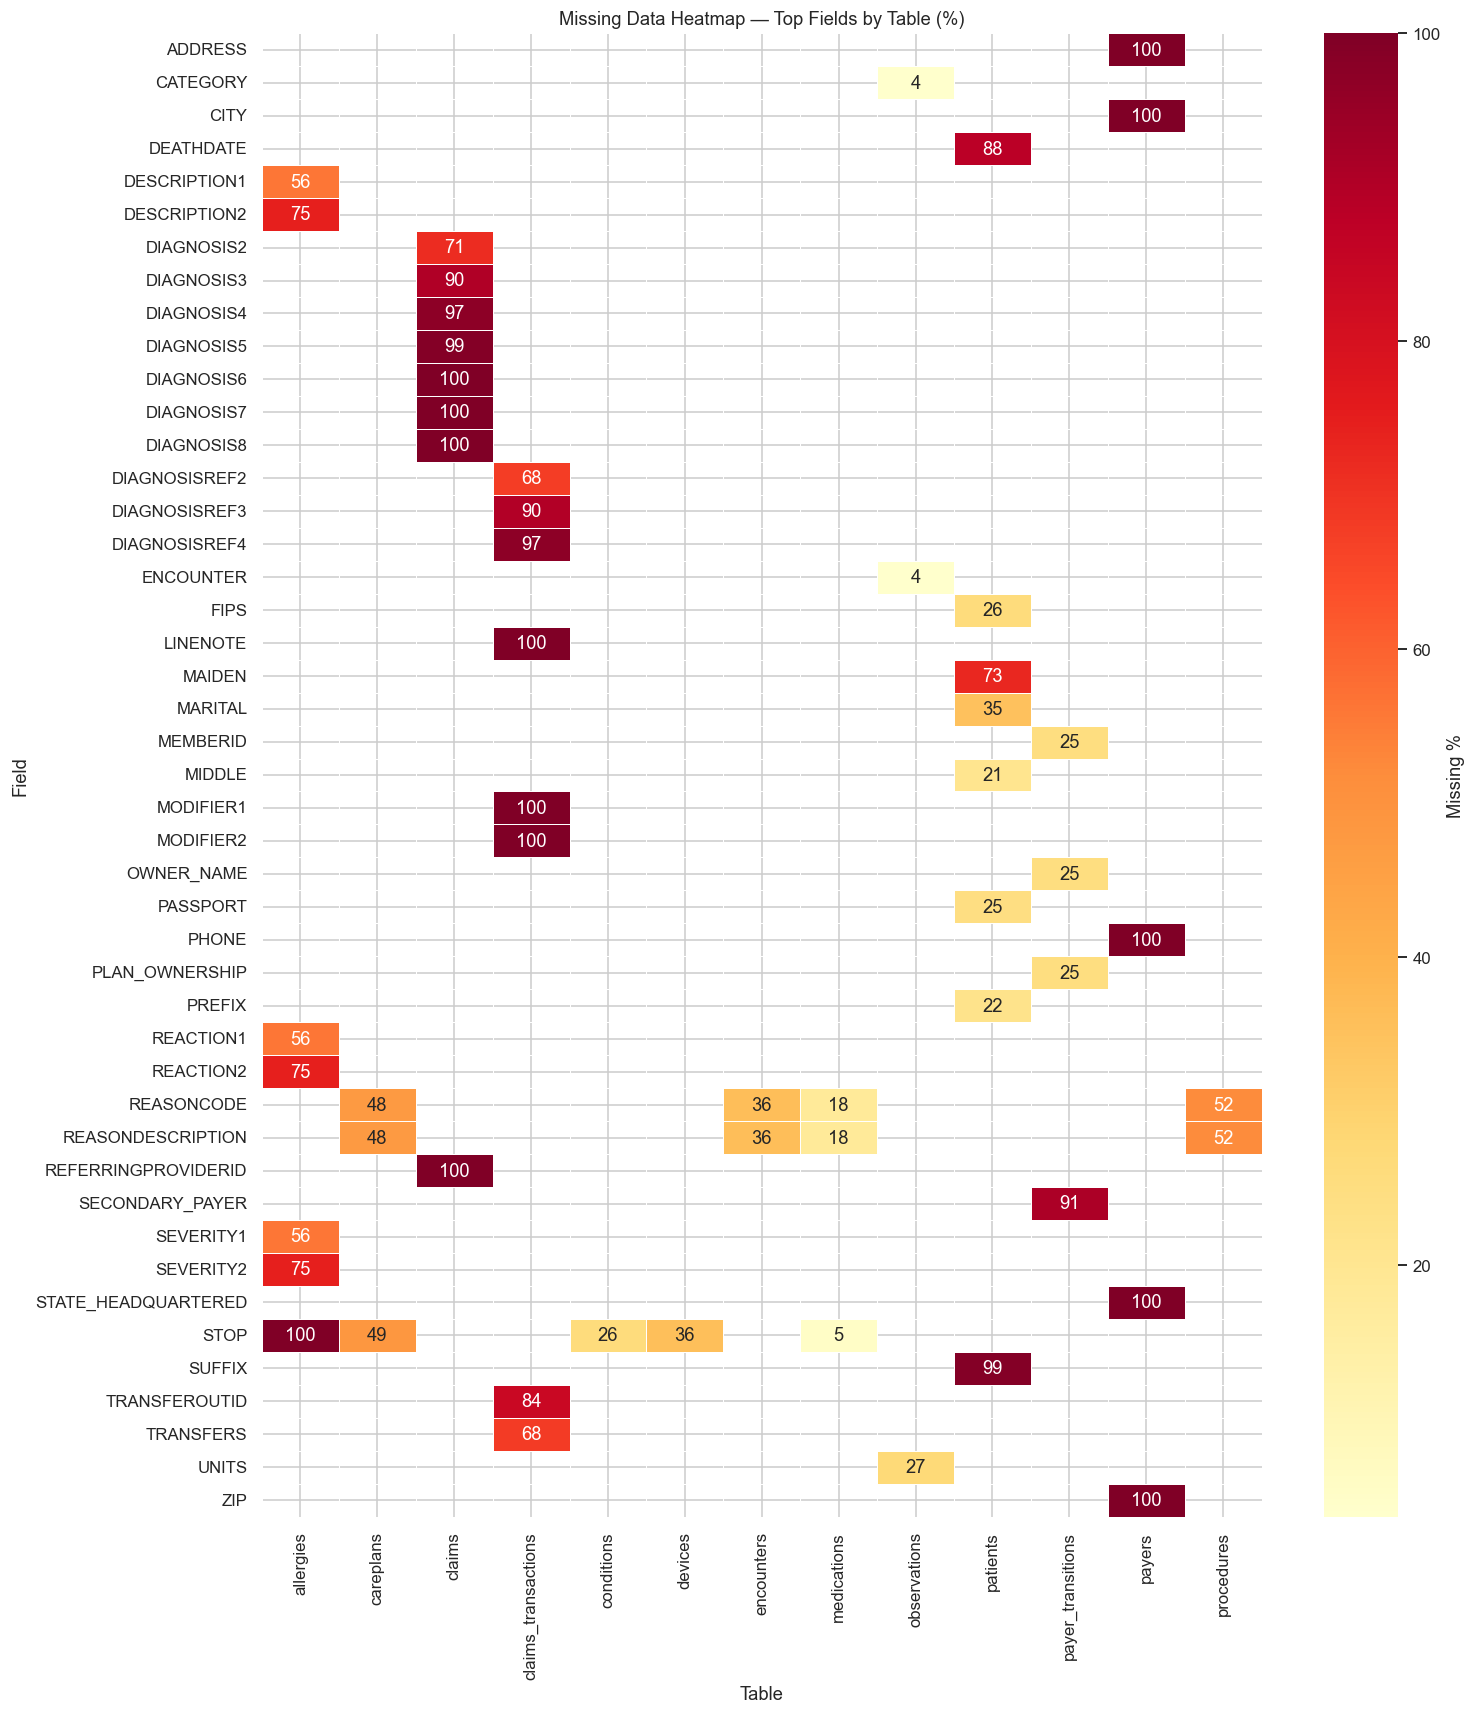

In [6]:
# Heatmap: missing % by table (top 15 columns with highest missingness per table)
plot_rows = []
for table_name, df in tables.items():
    null_pct = df.isna().mean() * 100
    for field, pct in null_pct.items():
        if pct > 0:
            plot_rows.append({"table": table_name, "field": field, "missing_pct": pct})

missing_plot_df = pd.DataFrame(plot_rows)
if missing_plot_df.empty:
    print("No missing values detected across any table.")
else:
    top_missing = (
        missing_plot_df.sort_values("missing_pct", ascending=False)
        .groupby("table", as_index=False)
        .head(8)
    )
    pivot = top_missing.pivot(index="field", columns="table", values="missing_pct")

    fig, ax = plt.subplots(figsize=(14, max(6, len(pivot) * 0.35)))
    sns.heatmap(
        pivot,
        annot=True,
        fmt=".0f",
        cmap="YlOrRd",
        linewidths=0.5,
        cbar_kws={"label": "Missing %"},
        ax=ax,
    )
    ax.set_title("Missing Data Heatmap — Top Fields by Table (%)")
    ax.set_xlabel("Table")
    ax.set_ylabel("Field")
    plt.tight_layout()
    plt.show()

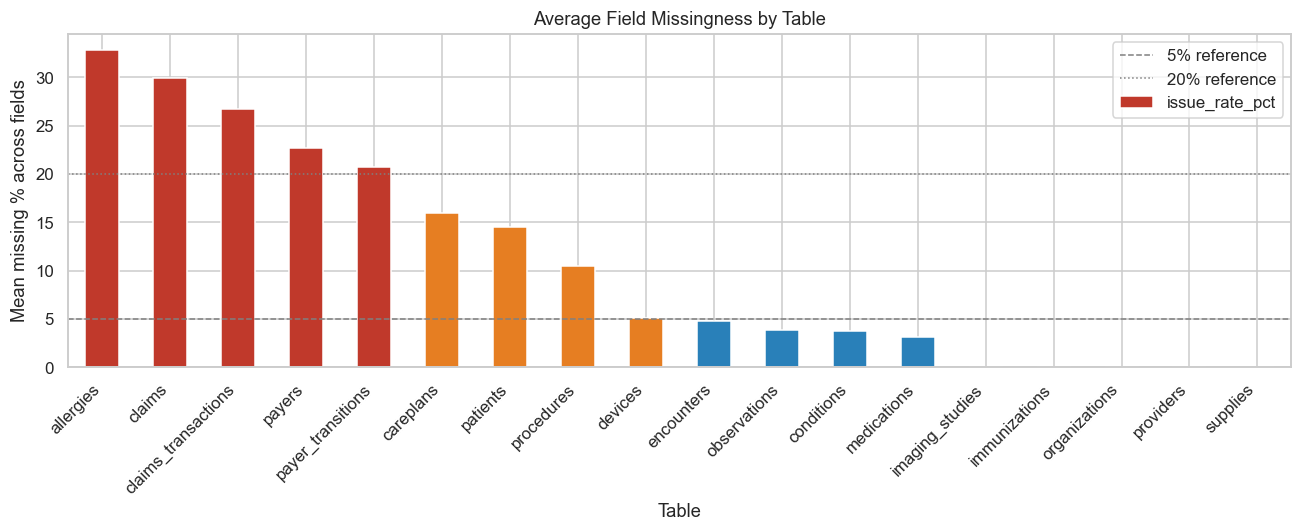

In [7]:
# Bar chart: average missingness by table
avg_missing_by_table = (
    completeness.groupby("table")["issue_rate_pct"].mean().sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(12, 5))
colors = ["#c0392b" if v > 20 else "#e67e22" if v > 5 else "#2980b9" for v in avg_missing_by_table]
avg_missing_by_table.plot(kind="bar", ax=ax, color=colors, edgecolor="white")
ax.set_title("Average Field Missingness by Table")
ax.set_xlabel("Table")
ax.set_ylabel("Mean missing % across fields")
ax.axhline(5, color="gray", linestyle="--", linewidth=1, label="5% reference")
ax.axhline(20, color="gray", linestyle=":", linewidth=1, label="20% reference")
ax.legend()
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 5. Uniqueness, Validity, and Referential Integrity

These dimensions confirm that patient identifiers are unique, coded values conform to expected domains, dates are parseable, and clinical event tables correctly link back to the patient registry — a prerequisite for reliable exposure and outcome attribution in RWE studies.

In [8]:
def show_dimension_table(dimension: str, columns: list[str] | None = None) -> None:
    subset = findings_df[findings_df["dimension"] == dimension].copy()
    if columns is None:
        columns = [
            "table",
            "field",
            "check_name",
            "total_records",
            "issue_count",
            "issue_rate_pct",
            "status",
            "details",
        ]
    print(f"\n{dimension} ({len(subset)} checks)")
    display(
        subset[columns].style.format(
            {
                "total_records": "{:,}",
                "issue_count": "{:,}",
                "issue_rate_pct": "{:.2f}%",
            }
        )
    )


show_dimension_table("Uniqueness")
show_dimension_table("Validity")
show_dimension_table("Referential Integrity")


Uniqueness (1 checks)


,table,field,check_name,total_records,issue_count,issue_rate_pct,status,details
256,patients,Id,duplicate_patient_ids,"1,135",0,0.00%,PASS,0 duplicated key value(s); 0 rows involved in duplication



Validity (16 checks)


,table,field,check_name,total_records,issue_count,issue_rate_pct,status,details
257,patients,BIRTHDATE,invalid_dates,"1,135",0,0.00%,PASS,Non-null values that fail ISO date/datetime parsing
258,patients,DEATHDATE,invalid_dates,"1,135",0,0.00%,PASS,Non-null values that fail ISO date/datetime parsing
259,encounters,START,invalid_dates,"66,657",0,0.00%,PASS,Non-null values that fail ISO date/datetime parsing
260,encounters,STOP,invalid_dates,"66,657",0,0.00%,PASS,Non-null values that fail ISO date/datetime parsing
261,conditions,START,invalid_dates,"40,022",0,0.00%,PASS,Non-null values that fail ISO date/datetime parsing
262,conditions,STOP,invalid_dates,"40,022",0,0.00%,PASS,Non-null values that fail ISO date/datetime parsing
263,medications,START,invalid_dates,"54,843",0,0.00%,PASS,Non-null values that fail ISO date/datetime parsing
264,medications,STOP,invalid_dates,"54,843",0,0.00%,PASS,Non-null values that fail ISO date/datetime parsing
265,allergies,CATEGORY,invalid_categorical_values,"1,086",0,0.00%,PASS,"Allowed domain: ['environment', 'food', 'medication']"
266,allergies,TYPE,invalid_categorical_values,"1,086",0,0.00%,PASS,"Allowed domain: ['allergy', 'intolerance']"



Referential Integrity (3 checks)


,table,field,check_name,total_records,issue_count,issue_rate_pct,status,details
273,encounters,PATIENT,encounters_to_patients,"66,657",0,0.00%,PASS,"0 orphan record(s) of 66,657 non-null FK values not found in patients.Id; 0 null FK value(s)"
274,conditions,PATIENT,conditions_to_patients,"40,022",0,0.00%,PASS,"0 orphan record(s) of 40,022 non-null FK values not found in patients.Id; 0 null FK value(s)"
275,medications,PATIENT,medications_to_patients,"54,843",0,0.00%,PASS,"0 orphan record(s) of 54,843 non-null FK values not found in patients.Id; 0 null FK value(s)"


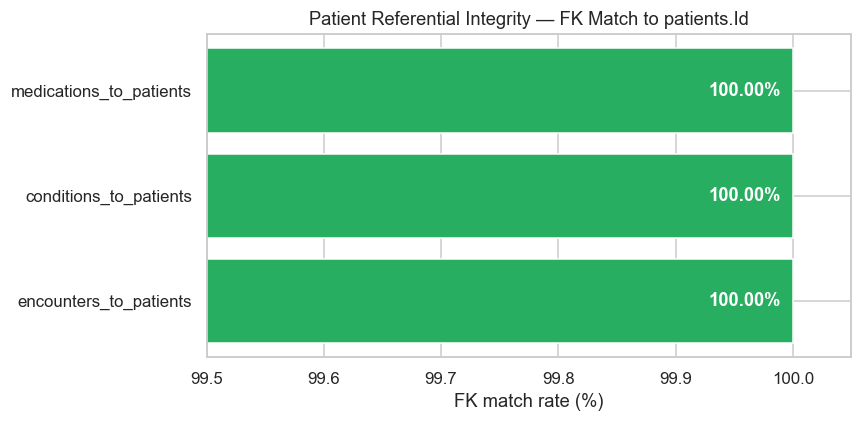

In [9]:
# Referential integrity visualization
ref_df = findings_df[findings_df["dimension"] == "Referential Integrity"].copy()
ref_df["match_rate_pct"] = 100 - ref_df["issue_rate_pct"]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(
    ref_df["check_name"],
    ref_df["match_rate_pct"],
    color="#27ae60",
    edgecolor="white",
)
ax.set_xlim(99.5, 100.05)
ax.set_xlabel("FK match rate (%)")
ax.set_title("Patient Referential Integrity — FK Match to patients.Id")
for bar, rate in zip(bars, ref_df["match_rate_pct"]):
    ax.text(bar.get_width() - 0.01, bar.get_y() + bar.get_height() / 2,
            f"{rate:.2f}%", va="center", ha="right", color="white", fontweight="bold")
plt.tight_layout()
plt.show()

## 6. RWE Analysis Report — Interpretation of Findings

The following narrative summarizes data quality results in the format typically submitted with an RWE study protocol or included in a Data Quality Report (DQR) for pharmaceutical regulatory submissions (e.g., FDA Sentinel, EMA ENCePP).

In [10]:
from IPython.display import Markdown, display

n_patients = len(tables["patients"])
n_encounters = len(tables["encounters"])
n_conditions = len(tables["conditions"])
n_medications = len(tables["medications"])

overall = summary["overall"]
fail_count = overall.get("FAIL", 0)
warn_count = overall.get("WARN", 0)

critical_missing = completeness[
    (completeness["is_critical"]) & (completeness["issue_count"] > 0)
]
high_missing_optional = completeness[
    (~completeness["is_critical"]) & (completeness["issue_rate_pct"] >= 50)
].sort_values("issue_rate_pct", ascending=False)

# Top optional fields with high missingness (documented, not defects)
top_optional = high_missing_optional.head(5)
optional_lines = "\n".join(
    f"- **{r.table}.{r.field}**: {r.issue_rate_pct:.1f}% missing ({r.issue_count:,} records)"
    for r in top_optional.itertuples()
) or "- No fields with ≥50% missingness among non-critical variables."

ref_lines = "\n".join(
    f"- **{r.check_name}**: {100 - r.issue_rate_pct:.2f}% of {int(r.total_records):,} "
    f"{r.table} records link to a valid patient ({int(r.issue_count):,} orphans)"
    for r in findings_df[findings_df["dimension"] == "Referential Integrity"].itertuples()
)

fit_for_use = "fit for purpose" if fail_count == 0 else "requires remediation before analytic use"

narrative = f"""
### Data Source Overview

The Synthea synthetic dataset comprises **{n_patients:,} unique patients** linked to
**{n_encounters:,} encounters**, **{n_conditions:,} condition records**, and
**{n_medications:,} medication dispensing records** across {len(tables)} relational tables.
Although synthetic, the data mirror the structure of claims/EHR-derived RWE sources used
in pharmacoepidemiology.

### Overall Assessment

A total of **{overall['total']} data quality checks** were executed across four dimensions.
Results: **{overall.get('PASS', 0)} PASS**, **{warn_count} WARN**, **{fail_count} FAIL**.

Based on pre-specified acceptance criteria, the dataset is considered **{fit_for_use}**
for downstream cohort definition and exposure/outcome analysis.

### Completeness

Critical analytic variables — including patient identifier, birth date, gender, encounter
dates, diagnosis codes, and medication codes — were **100% complete** with zero missing values.

Optional or clinically expected null fields showed higher missingness, consistent with
real-world data patterns:

{optional_lines}

These fields are not required for primary exposure/outcome ascertainment and reflect
structural nullability (e.g., ongoing conditions without a stop date, patients without
documented death, optional insurance fields on claims).

### Uniqueness

Patient identifier (`patients.Id`) demonstrated **zero duplicate values** across
{n_patients:,} records, confirming one-to-one mapping between patient keys and demographic
records. This supports reliable person-level linkage across clinical domains.

### Validity

All date fields in core clinical tables parsed successfully to ISO 8601 datetime formats.
Categorical fields (gender, race, ethnicity, marital status, encounter class) conformed
to pre-defined Synthea/OMOP-aligned code lists with **zero out-of-domain values**.

### Referential Integrity

Patient foreign keys in downstream clinical tables demonstrated **100% referential integrity**
to the patient registry:

{ref_lines}

No orphan records were detected, indicating consistent patient linkage suitable for
longitudinal RWE analyses.

### Recommendations

1. **Proceed** with cohort construction using `patients`, `encounters`, `conditions`, and
   `medications` as primary analytic tables.
2. **Document** expected missingness in optional fields within the Statistical Analysis Plan.
3. **Re-run** this assessment after any ETL transformation or data refresh to maintain audit trail.
4. Exported reports are available at `{REPORT_DIR}` (`data_quality_report.csv`, `data_quality_report.html`).
"""

display(Markdown(narrative))


### Data Source Overview

The Synthea synthetic dataset comprises **1,135 unique patients** linked to
**66,657 encounters**, **40,022 condition records**, and
**54,843 medication dispensing records** across 18 relational tables.
Although synthetic, the data mirror the structure of claims/EHR-derived RWE sources used
in pharmacoepidemiology.

### Overall Assessment

A total of **276 data quality checks** were executed across four dimensions.
Results: **276 PASS**, **0 WARN**, **0 FAIL**.

Based on pre-specified acceptance criteria, the dataset is considered **fit for purpose**
for downstream cohort definition and exposure/outcome analysis.

### Completeness

Critical analytic variables — including patient identifier, birth date, gender, encounter
dates, diagnosis codes, and medication codes — were **100% complete** with zero missing values.

Optional or clinically expected null fields showed higher missingness, consistent with
real-world data patterns:

- **allergies.STOP**: 100.0% missing (1,086 records)
- **payers.PHONE**: 100.0% missing (10 records)
- **payers.ZIP**: 100.0% missing (10 records)
- **claims.REFERRINGPROVIDERID**: 100.0% missing (121,500 records)
- **claims_transactions.MODIFIER2**: 100.0% missing (1,068,109 records)

These fields are not required for primary exposure/outcome ascertainment and reflect
structural nullability (e.g., ongoing conditions without a stop date, patients without
documented death, optional insurance fields on claims).

### Uniqueness

Patient identifier (`patients.Id`) demonstrated **zero duplicate values** across
1,135 records, confirming one-to-one mapping between patient keys and demographic
records. This supports reliable person-level linkage across clinical domains.

### Validity

All date fields in core clinical tables parsed successfully to ISO 8601 datetime formats.
Categorical fields (gender, race, ethnicity, marital status, encounter class) conformed
to pre-defined Synthea/OMOP-aligned code lists with **zero out-of-domain values**.

### Referential Integrity

Patient foreign keys in downstream clinical tables demonstrated **100% referential integrity**
to the patient registry:

- **encounters_to_patients**: 100.00% of 66,657 encounters records link to a valid patient (0 orphans)
- **conditions_to_patients**: 100.00% of 40,022 conditions records link to a valid patient (0 orphans)
- **medications_to_patients**: 100.00% of 54,843 medications records link to a valid patient (0 orphans)

No orphan records were detected, indicating consistent patient linkage suitable for
longitudinal RWE analyses.

### Recommendations

1. **Proceed** with cohort construction using `patients`, `encounters`, `conditions`, and
   `medications` as primary analytic tables.
2. **Document** expected missingness in optional fields within the Statistical Analysis Plan.
3. **Re-run** this assessment after any ETL transformation or data refresh to maintain audit trail.
4. Exported reports are available at `e:\rwe-project\reports` (`data_quality_report.csv`, `data_quality_report.html`).
